In [1]:
try:
    from myfm import MyFMClassifier, MyFMGibbsClassifier, VariationalFMClassifier
    # from myfm.utils.encoders import DataFrameEncoder
except:
    !pip install -q myfm
    from myfm import MyFMClassifier, MyFMGibbsClassifier, VariationalFMClassifier
    # from myfm.utils.encoders import DataFrameEncoder

# try:
#     from fastFM.als import FMClassification as als_Classification
#     from fastFM.sgd import FMClassification as sgd_Classification
# except:
#     !pip install -q fastFM
#     from fastFM.als import FMClassification as als_Classification
#     from fastFM.sgd import FMClassification as sgd_Classification

In [2]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'CPU: 4'

In [3]:
# !uv pip install -U scikit-learn

In [4]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [5]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random
from scipy.stats import norm

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep
from importlib.metadata import version

## -- Machine Learning --
from sklearn.calibration import CalibrationDisplay
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, TargetEncoder as sklearnTE

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 100)
# sns.set_style("whitegrid")
# plt.style.use('ggplot')

print("MyFm version:", version("myfm"))

MyFm version: 0.5.0


In [6]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [7]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")

TARGET, ID = 'is_fraud', 'id'

## -- Check if id is unique --
if ID in train.columns:
    if train.id.is_unique:
        print(f"Train ID column is unique: {train.id.is_unique}... Dropping!")
        train = train.drop(columns=[ID])
        test  = test.drop(columns=[ID])
        if ID in orig.columns:
            orig = orig.drop(columns=[ID])

Train ID column is unique: True... Dropping!


In [8]:
# train[TARGET] = train[TARGET].map({True: 1, False: 0})
# orig[TARGET] = orig[TARGET].map({True: 1, False: 0})

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()
bol = train.select_dtypes(include=[bool]).columns.tolist()

cat_cols  = [c for c in obj if c not in [TARGET]]
bool_cols = [c for c in bol if c not in [TARGET]]
num_cols  = [c for c in train.columns if c not in cat_cols+bool_cols+[TARGET]]
base_cols = [c for c in train.columns if c not in [TARGET]]

train = train[base_cols+[TARGET]]
orig  = orig[base_cols+[TARGET]]
test  = test[base_cols]

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name:5s} shape: {df.shape}")
    
print(f"\nDataFrame type: {type(train)}")
print(f"Total Numerical: {len(num_cols)}")
print(f"Total Categorical: {len(cat_cols)}")
print(f"Total Boolean: {len(bool_cols)}")
print(f"Total base features: {len(base_cols)}")

Train shape: (699960, 25)
Test  shape: (299984, 24)
Orig  shape: (20000, 25)

DataFrame type: <class 'pandas.core.frame.DataFrame'>
Total Numerical: 13
Total Categorical: 5
Total Boolean: 6
Total base features: 24


In [9]:
float_cols = [
    'amount_usd', 'hours_since_last_txn', 'distance_from_home_km',
    'account_balance_usd', 'velocity_score', 'merchant_risk_score',
]

train.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [10]:
train_len = len(train)
test_len  = len(test)

n_unique = train[base_cols].nunique().sort_values()
n_unique

used_vpn                            2
ip_country_mismatch                 2
is_ai_generated_scam_attempt        2
billing_shipping_mismatch           2
is_foreign_transaction              2
is_new_merchant                     2
cvv_retry_count                     4
prior_disputes                      5
auth_method                         5
channel                             5
card_type                           5
day_of_week                         7
device_type                         8
txn_count_last_24h                 12
merchant_category                  12
time_of_day_hour                   24
card_age_months                    49
customer_age                       64
velocity_score                    666
merchant_risk_score               950
hours_since_last_txn             3633
distance_from_home_km            4365
amount_usd                      13387
account_balance_usd             43317
dtype: int64

## FEATURE ENGINEERING

In [11]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class customTE(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}
        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)
        return X

In [12]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    pbar = tqdm(valid_features)
    for col in pbar:
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"
            pbar.set_description(f"Augmenting {col}")
            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df, on=col, how='left')

            orig_cols.append(new_col)

        pbar.set_description(f"Original augment complete!")

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if c.endswith(('_mean', '_max', '_min')):
                df[c] = df[c].fillna(global_mean)
            elif c.endswith('_median'):
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


In [13]:
train.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [14]:
v = 3291.06
k = -2
for k in range(-2, 3):
    s = np.rint(v * 10**4) #.astype("int64")
    print(s // 10**(k+4) % 10, end=' | ')
    print(v // (10**k) % 10)

6.0 | 5.0
0.0 | 0.0
1.0 | 1.0
9.0 | 9.0
2.0 | 2.0


In [15]:
FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
combined = pd.concat([train, test, orig], ignore_index=True)

digit_cols = []

for col in float_cols:
    scaled = np.rint(combined[col].fillna(0) * 10**4).astype("int64")
    for k in range(3):
        dig_col = f"{col}_digit{k}"
        combined[dig_col] = (scaled // 10**(k+4) % 10).astype('int8')
        # combined[dig_col] = (combined[col].fillna(0) // (10**k) % 10).astype('int32').astype('category')
        digit_cols.append(dig_col)

train = combined.iloc[:train_len]
test = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig = combined.iloc[-len(orig):]

# Check nunique, and find which ones are < 2
unique_counts = train[digit_cols].nunique()
drop_cols = unique_counts[unique_counts < 2].index.tolist()

# update list for keep
digit_cols = [i for i in set(digit_cols) if i not in set(drop_cols)]

# drop constant features
train = train.drop(columns=drop_cols)
test  = test.drop(columns=drop_cols)
orig  = orig.drop(columns=drop_cols)

del combined
print(f"Total digit features: {len(digit_cols)}\n")

train[digit_cols].nunique()

Total digit features: 15



merchant_risk_score_digit1      10
account_balance_usd_digit2      10
distance_from_home_km_digit0    10
velocity_score_digit1            8
amount_usd_digit1               10
account_balance_usd_digit0      10
account_balance_usd_digit1      10
hours_since_last_txn_digit0     10
merchant_risk_score_digit2       2
merchant_risk_score_digit0      10
hours_since_last_txn_digit1      6
velocity_score_digit0           10
distance_from_home_km_digit1     6
amount_usd_digit2               10
amount_usd_digit0               10
dtype: int64

In [16]:
## -- Factorize cat_cols -- ⚠️

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Total features before operation:", len(FEATURES))

combined = pd.concat([train, test, orig], ignore_index=True)

for c in tqdm(cat_cols+bool_cols, desc="factorize_cats"):
    combined[c], _ = pd.factorize(combined[c], sort=True)

# for c in tqdm(cat_cols+bool_cols, desc="categorize_cats"):
#     combined[c] = combined[c].astype("category")

train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

del combined
print("Total features after operation:", len(FEATURES))

Total features before operation: 39


factorize_cats:   0%|          | 0/11 [00:00<?, ?it/s]

Total features after operation: 39


In [17]:
n = 138.73

str(n).split('.')

['138', '73']

In [18]:
# ## -- Create leading features --
# combined = pd.concat([train, test, orig]).reset_index(drop=True)

# lead_cols = []

# for c in float_cols:
#     lead1 = f"{c}_LEAD_1"
#     lead2 = f"{c}_LEAD_2"
    
#     # Convert to string and split across the decimal point for each row
#     split_df = combined[c].astype(str).str.split('.', expand=True)

#     combined[lead1] = split_df[0]
#     combined[lead2] = split_df[1]
    
#     # Optional: Fill missing fractional parts (e.g., if a number was 12 instead of 12.0)
#     combined[lead2] = combined[lead2].fillna(0)

#     lead_cols.append(lead1)
#     lead_cols.append(lead2)

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# # Check nunique, and find which ones are < 2
# unique_counts = train[lead_cols].nunique()
# drop_cols = unique_counts[unique_counts < 2].index.tolist()

# # update list for keep
# lead_cols = [i for i in set(lead_cols) if i not in drop_cols]

# # drop constant features
# train = train.drop(columns=drop_cols)
# test  = test.drop(columns=drop_cols)
# orig  = orig.drop(columns=drop_cols)

# del combined
# print(f"\n*** Total lead features: {len(lead_cols)}")

# print(train[lead_cols].nunique(dropna=False))
# train[lead_cols].head()

In [19]:
FEATURES = [c for c in train.columns if c not in [ID, TARGET]]

print(f"Train shape {train.shape}")

Train shape (699960, 40)


In [20]:
all_predictions = {}

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

USE_FULL_TRAIN = True
x_sample, x_sample2 = train_test_split(
    train,
    train_size=0.3,
    stratify=train[TARGET],
    random_state=42,
)

train_X = train.copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)

print(train_X.shape, type(train_X))
train_X.head()

(699960, 40) <class 'pandas.core.frame.DataFrame'>


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud,amount_usd_digit0,amount_usd_digit1,amount_usd_digit2,hours_since_last_txn_digit0,hours_since_last_txn_digit1,distance_from_home_km_digit0,distance_from_home_km_digit1,account_balance_usd_digit0,account_balance_usd_digit1,account_balance_usd_digit2,velocity_score_digit0,velocity_score_digit1,merchant_risk_score_digit0,merchant_risk_score_digit1,merchant_risk_score_digit2
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,5,2,3,4,7,0,0,0,0,0,0,0.0,1,6,0,9,0,7,1,9,6,2,5,0,9,2,0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,7,4,4,2,1,0,0,0,0,0,0,0.0,4,2,0,1,0,3,1,3,3,2,3,3,9,2,0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,11,4,3,3,5,0,0,1,0,0,0,0.0,6,0,0,1,0,8,0,6,4,0,5,3,4,2,0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,5,2,0,4,1,0,0,0,0,0,0,0.0,7,3,0,5,0,8,0,7,1,2,0,2,1,4,0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,1,4,0,3,6,0,0,0,0,0,0,0.0,3,5,6,0,0,1,1,1,9,2,4,3,8,4,0


# ML TRAINING

In [21]:
y_ = np.ascontiguousarray(train[TARGET], dtype=np.float64)
_y = np.where(train[TARGET] == 1, 1, -1)

print(np.unique(y_), np.unique(_y))
print(y_[:5], _y[:5])

[0. 1.] [-1  1]
[0. 0. 0. 0. 0.] [-1 -1 -1 -1 -1]


In [22]:
def Trainer_CV(
    model_name, params, train_df, test_df, features, target, kfold,
    use_ohe=False, use_original=False,
):
    print(f"\n===== Starting CV: {model_name} | {get_system_info()} =====")
    t0 = time()

    X = train_df[features]
    y = train_df[target].astype('int8')

    oof_preds  = np.zeros(len(X))
    test_preds = np.zeros(len(test_df))

    fold_scores = []
    feature_importances  = []

    for idx, (train_idx, val_idx) in enumerate(kfold.split(X, y), 1):
        print(f"\n+++ FOLD {idx}/{kfold.n_splits}")

        ## -- Split data for the current fold
        X_train, X_valid = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_valid = y.iloc[train_idx], y.iloc[val_idx]
        X_test = test_df[features].copy()

        # ## -- OPTION A: CONCATENATE ORIGINAL DATA --
        # if use_orig:
        #     X_train = pd.concat([X_train, orig[features]], ignore_index=True)
        #     y_train = pd.concat([y_train, orig[target]], ignore_index=True)
        #     # y_train = np.concatenate([y_train, orig[TARGET].values], axis=0)

        if idx == 1: display(X_train.head(3))
        print(f"⚙️ -> train={X_train.shape}, valid={X_valid.shape}", end=" | ")

        rank = params["rank"]
        # -- Expose encoder's categories for filtering
        if use_ohe:
            # if params["n_iter"] == 100:
            #     keep = 50
            # elif params["n_iter"] == 200:
            #     keep = 150
            # elif params["n_iter"] == 300:
            #     keep = 250
            # else:
            keep = int(np.floor(params["n_iter"] * 0.8))

            print(f"One-Hot-Encoding * Rank={rank} * Keep={keep}")
            ohe_ = OneHotEncoder(handle_unknown='ignore').fit(X_train)
            transformed_valid = ohe_.transform(X_valid)

            group_shapes = [len(group) for group in ohe_.categories_]
            print(f"⚙️ -> Group shapes: {group_shapes}")
        else:
            keep = 10
            print(f"Scaling raw features * Rank={rank} * Keep={keep}")
            scaler = StandardScaler().fit(X_train)
            transformed_valid = scaler.transform(X_valid)

            group_shapes = [i for i, col in enumerate(X_train.columns)]
            print(f"⚙️ -> Column indicators: {group_shapes}")
        # -------------------------------------------------------------------
        if "MyFM" in model_name:
            myfm_params = {'rank': rank, 'init_stdev': params["init_stdev"], 'random_seed': 42}
            model_type  = "myfm_gibbs" if "gib" in model_name else "myfm_var"
            model = Pipeline(
                [
                    ("ohe", OneHotEncoder(handle_unknown='ignore')) if use_ohe else ("sca", StandardScaler()),
                    (
                        model_type, MyFMClassifier(**myfm_params),
                    ) if "gib" in model_name else (
                        model_type, VariationalFMClassifier(**myfm_params),
                    )
                ],
                verbose=True,
            )
            print(f"⚙️ -> Training model: '{model_name}' ...\n")
            model.fit(**{
                'X': X_train,
                'y': y_train.values,
                f"{model_type}__X_test": transformed_valid,
                f"{model_type}__y_test": y_valid.values,
                f"{model_type}__n_iter": params["n_iter"],
                f"{model_type}__n_kept_samples": keep,
                f"{model_type}__grouping": None if use_ohe else group_shapes,
                f"{model_type}__group_shapes": group_shapes if use_ohe else None,
            } if "gib" in model_name else {
                'X': X_train,
                'y': y_train.values,
                f"{model_type}__X_test": transformed_valid,
                f"{model_type}__y_test": y_valid.values,
                f"{model_type}__n_iter": params["n_iter"],
                # f"{model_type}__n_kept_samples": keep,
                f"{model_type}__grouping": None if use_ohe else group_shapes,
                f"{model_type}__group_shapes": group_shapes if use_ohe else None,
            })
        elif "fastfm_als" in model_name:
            model = Pipeline(
                [
                    ("ohe", OneHotEncoder(handle_unknown='ignore')),
                    ("fast_als", als_Classification(**params, random_state=42)),
                ],
                verbose=True,
            )
            y_train = np.where(y_train == 1, 1.0, -1.0)
            print(f"⚙️ -> Training model: '{model_name}' ...\n")
            model.fit(X_train, y_train)
        else:
            model = Pipeline(
                [
                    ("ohe", OneHotEncoder(handle_unknown='ignore')),
                    ("fast_sgd", sgd_Classification(**params)),
                ],
                verbose=True,
            )
            y_train = np.where(y_train == 1, 1.0, -1.0)
            print(f"⚙️ -> Training model: '{model_name}' ...")
            model.fit(X_train, y_train)
        # -----------------------------------------------------------------------

        oof_preds[val_idx] = model.predict_proba(X_valid)
        test_preds += model.predict_proba(X_test)

        # Calculate fold score
        fold_score = np.round(roc_auc_score(y_valid, oof_preds[val_idx]), 5)
        fold_scores.append(fold_score)
        # print(f"{CFG['YELLOW']} • Fold {idx} AUC: {fold_score:.5f}{CFG['RESET']}")
        print(f"{Fore.YELLOW}{Style.BRIGHT} • Fold {idx} AUC: {fold_score:.5f}{Style.RESET_ALL}")

        # Clean up memory
        del X_train, y_train, y_valid, model
        gc.collect()

    # Average test predictions
    test_preds /= kfold.n_splits
    
    ## -- CV results --
    print("\n========================================")
    print(f"{kfold.n_splits}-FOLD CV: {model_name} | {X_test.shape}")
    print("========================================")
    for i, s in enumerate(fold_scores, 1):
        print(f" • Fold {i} AUC: {s}")

    ## -- Out-of-fold AUC --
    oof_score = np.round(roc_auc_score(y, oof_preds), 5)
    avg_score = np.round(np.mean(fold_scores), 5)
    std_score = np.round(np.std(fold_scores), 5)

    print("---------------------------------------")
    print(f"OOF AUC: {Fore.YELLOW}{Style.BRIGHT}{oof_score}{Style.RESET_ALL}")
    print(f"AVG AUC: {Fore.YELLOW}{Style.BRIGHT}{avg_score} ± {std_score}{Style.RESET_ALL}")
    print("---------------------------------------")
    print(f"{(time()-t0)/60:.3g} mins\n")

    return {
        'oof_preds': oof_preds,
        'test_preds': test_preds,
        'score': avg_score,
        # 'model': model,
    }

print("⚙️ Training function ready ⚙️")

⚙️ Training function ready ⚙️


In [23]:
## --- Trainer ---

# f"fm_myfm_gibbs{params["rank"]}", f"fm_myfm_var{params["rank"]}"
# f"fm_fastfm_als{params["rank"]}", f"fm_fastfm_sgd{params["rank"]}"

for use_OHE in [True]:
    n_iters = 500
    ranking = 1 if use_OHE else 4
    ini_std = 0.3 if use_OHE else 0.1

    gibbs = f"MyFM_gib{ranking}_{ini_std}_{n_iters}_"
    varss = f"MyFM_var{ranking}_{ini_std}_{n_iters}_"

    for n in [varss]:
        params = {
            "n_iter": n_iters,
            "rank": ranking,
            "init_stdev": ini_std, # 0.1, 0.2, 0.5, 1.0
            # "l2_reg_w": 1.0, # 0.1
            # "l2_reg_V": 1.0, # 0.5
            # "l2_reg": 1.0, # 1.0
        }
        all_predictions[n] = Trainer_CV(
            model_name=n,
            params=params,
            train_df=train_X,
            test_df=test,
            features=FEATURES,
            target=TARGET,
            kfold=skf,
            use_ohe=use_OHE,
            # use_original=True,
        )


===== Starting CV: MyFM_var1_0.3_500_ | CPU: 4 =====

+++ FOLD 1/5


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,amount_usd_digit0,amount_usd_digit1,amount_usd_digit2,hours_since_last_txn_digit0,hours_since_last_txn_digit1,distance_from_home_km_digit0,distance_from_home_km_digit1,account_balance_usd_digit0,account_balance_usd_digit1,account_balance_usd_digit2,velocity_score_digit0,velocity_score_digit1,merchant_risk_score_digit0,merchant_risk_score_digit1,merchant_risk_score_digit2
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,7,4,4,2,1,0,0,0,0,0,0,4,2,0,1,0,3,1,3,3,2,3,3,9,2,0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,11,4,3,3,5,0,0,1,0,0,0,6,0,0,1,0,8,0,6,4,0,5,3,4,2,0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,5,2,0,4,1,0,0,0,0,0,0,7,3,0,5,0,8,0,7,1,2,0,2,1,4,0


⚙️ -> train=(559968, 39), valid=(139992, 39) | One-Hot-Encoding * Rank=1 * Keep=400
⚙️ -> Group shapes: [12544, 3553, 12, 4303, 49, 64, 39978, 4, 660, 24, 7, 944, 5, 12, 5, 5, 5, 8, 2, 2, 2, 2, 2, 2, 10, 10, 10, 10, 6, 10, 6, 10, 10, 10, 10, 8, 10, 10, 2]
⚙️ -> Training model: 'MyFM_var1_0.3_500_' ...

[Pipeline] ............... (step 1 of 2) Processing ohe, total=   2.6s


w0 = -2.37  ll_this: 0.05 accuracy_this: 0.99: 100%|██████████| 500/500 [13:15<00:00,  1.59s/it]


[Pipeline] .......... (step 2 of 2) Processing myfm_var, total=13.3min
 • Fold 1 AUC: 0.94607

+++ FOLD 2/5
⚙️ -> train=(559968, 39), valid=(139992, 39) | One-Hot-Encoding * Rank=1 * Keep=400
⚙️ -> Group shapes: [12602, 3547, 12, 4307, 49, 64, 40115, 4, 658, 24, 7, 947, 5, 12, 5, 5, 5, 8, 2, 2, 2, 2, 2, 2, 10, 10, 10, 10, 6, 10, 6, 10, 10, 10, 10, 8, 10, 10, 2]
⚙️ -> Training model: 'MyFM_var1_0.3_500_' ...

[Pipeline] ............... (step 1 of 2) Processing ohe, total=   2.1s


w0 = -3.97  ll_this: 0.05 accuracy_this: 0.99: 100%|██████████| 500/500 [12:15<00:00,  1.47s/it]


... (3 outputs left out)

w0 = -2.97  ll_this: 0.05 accuracy_this: 0.99: 100%|██████████| 500/500 [13:36<00:00,  1.63s/it]


[Pipeline] .......... (step 2 of 2) Processing myfm_var, total=13.6min
 • Fold 4 AUC: 0.94656

+++ FOLD 5/5
⚙️ -> train=(559968, 39), valid=(139992, 39) | One-Hot-Encoding * Rank=1 * Keep=400
⚙️ -> Group shapes: [12567, 3562, 12, 4301, 49, 64, 40068, 4, 660, 24, 7, 942, 5, 12, 5, 5, 5, 8, 2, 2, 2, 2, 2, 2, 10, 10, 10, 10, 6, 10, 6, 10, 10, 10, 10, 8, 10, 10, 2]
⚙️ -> Training model: 'MyFM_var1_0.3_500_' ...

[Pipeline] ............... (step 1 of 2) Processing ohe, total=   2.6s


w0 = -1.55  ll_this: 0.05 accuracy_this: 0.99: 100%|██████████| 500/500 [12:04<00:00,  1.45s/it]


[Pipeline] .......... (step 2 of 2) Processing myfm_var, total=12.1min
 • Fold 5 AUC: 0.94164

5-FOLD CV: MyFM_var1_0.3_500_ | (299984, 39)
 • Fold 1 AUC: 0.94607
 • Fold 2 AUC: 0.94854
 • Fold 3 AUC: 0.95183
 • Fold 4 AUC: 0.94656
 • Fold 5 AUC: 0.94164
---------------------------------------
OOF AUC: 0.94691
AVG AUC: 0.94693 ± 0.00333
---------------------------------------
64.6 mins



In [24]:
# ===================== iter=500 | std=0.1
# 5-FOLD CV: MyFM_gib1_ | (559968, 39)
# ========================================
#  • Fold 1 AUC: 0.94359
#  • Fold 2 AUC: 0.94682
#  • Fold 3 AUC: 0.95051
#  • Fold 4 AUC: 0.94471
#  • Fold 5 AUC: 0.93952
# ---------------------------------------
# OOF AUC: 0.94499
# AVG AUC: 0.94503 ± 0.00363
# ---------------------------------------
# 20.9 mins

# ========================================
# 5-FOLD CV: MyFM_var1_0.3_300_ | (299984, 39)
# ========================================
#  • Fold 1 AUC: 0.94611
#  • Fold 2 AUC: 0.94857
#  • Fold 3 AUC: 0.95175
#  • Fold 4 AUC: 0.94644
#  • Fold 5 AUC: 0.94149
# ---------------------------------------
# OOF AUC: 0.94686
# AVG AUC: 0.94687 ± 0.00336
# ---------------------------------------
# 37.3 mins

# ========================================
# 5-FOLD CV: MyFM_var1_0.3_500_ | (299984, 39)
# ========================================
#  • Fold 1 AUC: 0.94607
#  • Fold 2 AUC: 0.94854
#  • Fold 3 AUC: 0.95183
#  • Fold 4 AUC: 0.94656
#  • Fold 5 AUC: 0.94164
# ---------------------------------------
# OOF AUC: 0.94691
# AVG AUC: 0.94693 ± 0.00333
# ---------------------------------------
# 60.3 mins

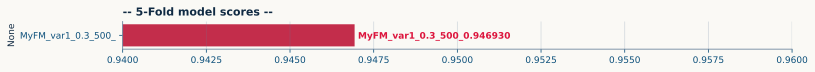

In [25]:
## -- Get Scores --
all_scores = {k: v.get("score") for k, v in all_predictions.items() if "score" in v}
results_df = pd.Series(all_scores).sort_values(ascending=False).round(5) #[:10]

max_val = results_df.max()
palette = [CRIM if c == max_val else MUTED for c in results_df.values]

plt.figure(figsize=(12, len(results_df)*0.5))

ax1 = sns.barplot(
    x=results_df.values,
    y=results_df.index,
    palette=palette,
    hue=results_df.index,
    orient="h",
    legend=False,
)

for i, s1 in enumerate(results_df.values):
    ax1.text(
        s1+1e-4,
        float(i),
        f"{results_df.index[i]}{s1:.6f}" if s1 == max_val else f"{results_df.index[i]}{s1:.6f}",
        ha="left",
        va='center_baseline',
        weight="semibold",
        color=CRIM if s1 == max_val else MUTED,
    )

plt.title(f"-- {FOLDS}-Fold model scores --", loc='left')
plt.xlim((0.94, 0.96))
plt.tight_layout()
plt.show()

MyFM_var1_0.3_500__94693 saved!


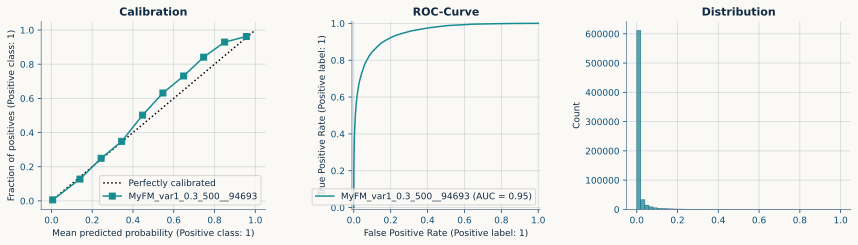

In [26]:
## -- Get oof predictions --

for i, (k, v) in enumerate(all_predictions.items()):
    for key_, data_ in v.items():
        if key_ == "oof_preds":
            ## -- Save oof predictions --
            n = f"{k}_{str(all_scores[k]).split('.')[1]}"
            np.save(f"oof_{n}.npy", data_)
            print(f"{n} saved!")

            ## -- Plot oof distributions --
            _, axs = plt.subplots(1, 3, figsize=(12, 3.5)) 
            CalibrationDisplay.from_predictions(train_X[TARGET], data_, n_bins=10, name=n, ax=axs[0])
            axs[0].set_title(f"Calibration")

            RocCurveDisplay.from_predictions(train_X[TARGET], data_, name=n, ax=axs[1])
            axs[1].set_title(f"ROC-Curve")

            sns.histplot(data_, bins=50, ax=axs[2])
            axs[2].set_title(f"Distribution")
            
            plt.tight_layout()
            plt.show()

            print()

In [27]:
## -- Save test predictions/submissions --
model_results = {}

for i, (k, v) in enumerate(all_predictions.items()):
    for j, (x, y) in enumerate(v.items()):
        if x == "test_preds":
            ## -- Base submission file --
            n = f"{k}_{str(all_scores[k]).split('.')[1]}"
            np.save(f"test_{n}.npy", y)

            submit[TARGET] = y
            submit.to_csv(f"submit_{n}.csv", index=False)
            print(f"{n} saved! {y.shape}")

            model_results[n[:-6]] = y

print()
model_results = pd.DataFrame(model_results)
model_results

MyFM_var1_0.3_500__94693 saved! (299984,)



,MyFM_var1_0.3_500_
0,0.000021
1,0.000003
2,0.060715
3,0.000364
4,0.000413
...,...
299979,0.000430
299980,0.002100
299981,0.049206
299982,0.000004


In [28]:
model_results.describe().T

,count,mean,std,min,25%,50%,75%,max
MyFM_var1_0.3_500_,299984.0,0.01667,0.069305,2.147604e-12,0.000089,0.000803,0.005572,0.999986


In [29]:
mdls = model_results.shape[1]

if mdls > 1:
    # display(model_results.corr("spearman"))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    sns.heatmap(model_results.corr("spearman"), annot=True, fmt=".4g", cbar=False, ax=ax1)
    ax1.set_title('Heatmap Correlation (Spearman)')
    
    sns.ecdfplot(data=model_results, linewidth=2, ax=ax2)
    ax2.set_title(f"CDF Comparison of ({mdls}) Probability distributions")
    ax2.set_xlabel('Probability Value')
    ax2.set_ylabel('Cumulative Proportion (CDF)')
    ax2.grid(True, linestyle='--')

    plt.tight_layout(pad=2.0)
    plt.show()

In [30]:
# !rm -r /kaggle/working